### Problem statement
System: In -> A -> B -> C

<br>

**In $\rightarrow$ A:** Transform Qubit Readout data. Messages arrive with fixed mean arrival rate $\lambda$. Infinite queue if stage A blocked.

**A:** Read message. Processing time $\mathrm{Uniform}(1.5, 2.2)\mu s$.

**A $\rightarrow$ B:** FIFO buffer. Capacity = 100. If full A stops

**B:** Log-Normal distribution processing time $\mu = 0.5 , \sigma ^2 = 0.5$

**B $\rightarrow$ C:** FIFO buffer. Capacity = 25. If full B stops

**C:** Constant time of $1.5\mu s$

In [17]:
import numpy as np
import math
from scipy.special import factorial
import matplotlib.pyplot as plt

4384
0.4383999999307978
A utilisation:  0.9909339582256818
B utilisation:  1.0001684351483147
C utilisation:  0.657749999896173
[0.16100000000000012, 3.176999999999761, 3.8639999999996855, 4.144999999999719, 4.323999999999779, 5.790000000000268, 6.954000000000657, 6.980000000000666, 15.078999999997082, 15.294999999996962, 15.685999999996746, 17.162999999997993, 17.297999999998158, 18.131999999999177, 20.088000000001568, 20.10700000000159, 21.111000000002818, 21.403000000003175, 21.89900000000378, 23.398000000005613, 25.791000000008538, 27.067000000010097, 28.503000000011852, 29.545000000013125, 31.105000000015032, 31.62600000001567, 32.94800000001391, 33.634000000012314, 34.48900000001032, 35.95200000000691, 36.28300000000614, 37.66800000000291, 37.71100000000281, 37.72000000000279, 37.83200000000253, 39.532999999998566, 39.72899999999811, 41.202999999994674, 41.90499999999304, 42.128999999992516, 42.32899999999205, 42.592999999991434, 44.935999999985974, 47.46099999998009, 48.72399999

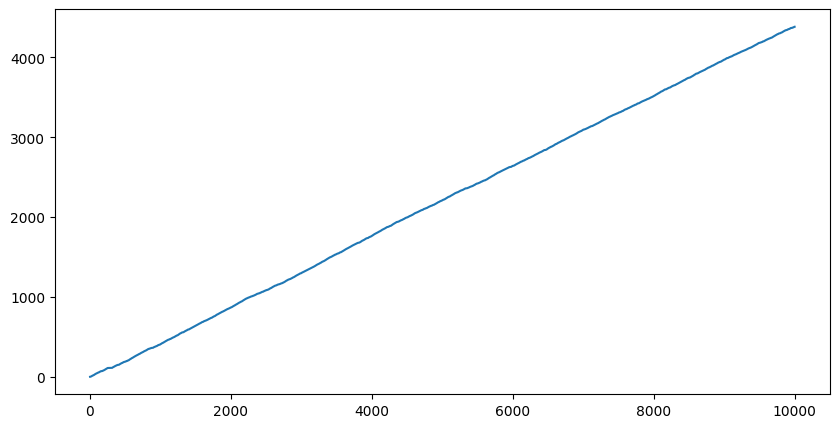

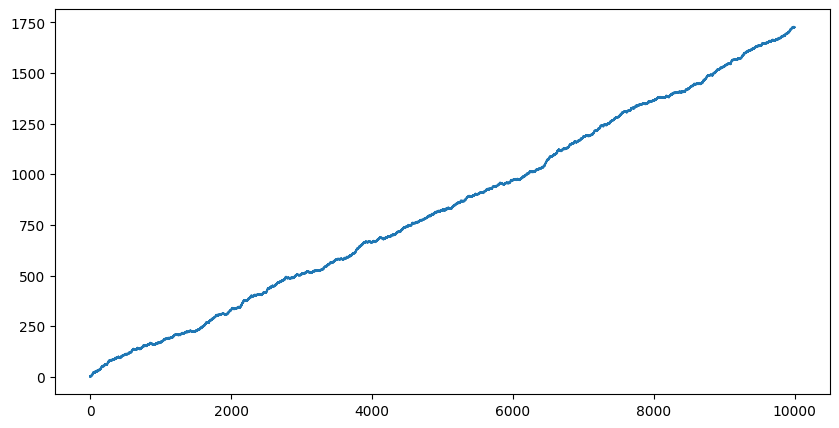

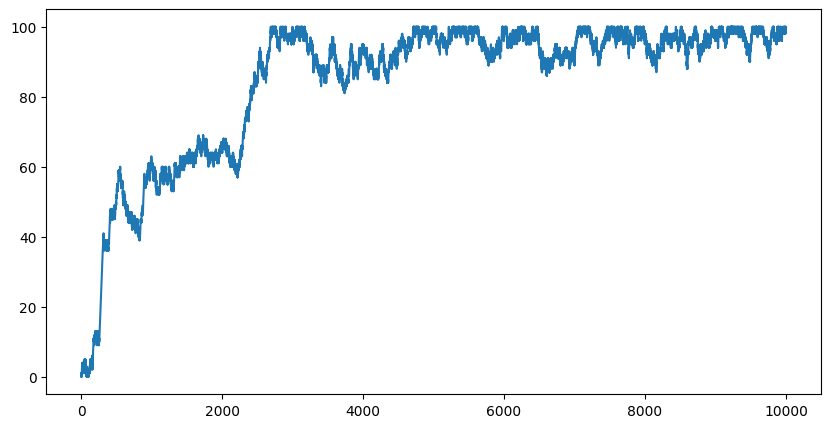

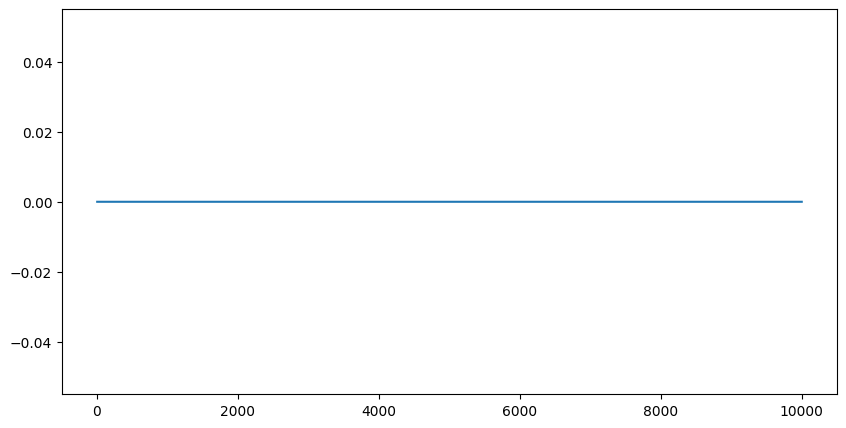

In [172]:
class Queue:
    def __init__(self, max_length):
        self.length = 0
        self.max_length = max_length

class Source:
    def __init__(self, lam):
        self.lam = lam

    def next_arrival(self):
        return np.random.exponential(scale=self.lam)

b_queue = Queue(100)
c_queue = Queue(25)
a_queue = Queue(1e8)
    
source = Source(1.5)
ts = 0.001
max_time = 10000

time = 0.0
a_time = 0.0
b_time = 0.0
c_time = 0.0

a_time_on = 0.0
b_time_on = 0.0
c_time_on = 0.0

a_stopped = False
b_stopped = False
c_busy = False

total_throughput = 0
cumulative_through = []

qubit_in_list = []
qubit_out_list = []

qubits_in_a = 0
qubits_in_b = 0
qubits_in_c = 0

stop = False

next_a_arrival = source.next_arrival()

callbacks = {
    'a_queue_lengths': [],
    'b_queue_lengths': [],
    'c_queue_lengths': []
}


# TODO: check utilisation for last bit
# TODO: remove utilisation when system disabled
while time < max_time:
    
    if next_a_arrival < ts:
        a_queue.length += 1

        qubit_in_list += [time]
        
        # print(qubit_in)
        next_a_arrival = source.next_arrival()
        # print('IN', time, next_a_arrival)

        callbacks['a_queue_lengths'] += [(a_queue.length, time)]

    if (a_queue.length > 0) & (a_time < ts) & (not a_stopped):
        
        qubits_in_a += 1
        
        a_queue.length -= 1
        a_time = np.random.random() + 1.5

        a_time_on += a_time

        callbacks['a_queue_lengths'] += [(a_queue.length, time)]

        if (b_queue.length < b_queue.max_length) & (qubits_in_a > 1):
            b_queue.length += 1
            callbacks['b_queue_lengths'] += [(b_queue.length, time)]
        elif qubits_in_a > 1:
            a_stopped = True
        else:
            pass

    if (b_queue.length > 0) & (b_time < ts) & (not b_stopped):
        qubits_in_b += 1
        b_queue.length -= 1
        callbacks['b_queue_lengths'] += [(b_queue.length, time)]
        a_stopped = False
        # print('B', time, c_queue.length)

        b_time = np.random.lognormal(mean=0.5, sigma=np.sqrt(0.5))
        # print(b_time)
        b_time_on += b_time

        if c_queue.length < c_queue.max_length & (qubits_in_b > 1):
            c_queue.length += 1
            # callbacks['c_queue_lengths'] += [(c_queue.length/, time)]
        elif qubits_in_b > 1:
            b_stopped = True
        else:
            pass

    if (c_queue.length > 0) & (c_time < ts):
        qubits_in_c += 1
        c_queue.length -= 1
        b_stopped = False
        # print('OUT', time)
        # print('OUT',c_queue.length, qubit_out)
        callbacks['c_queue_lengths'] += [(c_queue.length, time)]
        c_time = 1.5
        
        c_time_on += 1.5

        if(c_queue.length >1):
            print('############', c_queue.length)

        if qubits_in_c > 1:
            qubit_out_list += [time]
            total_throughput += 1
            cumulative_through += [time]

    # callbacks['a_queue_lengths'] += [(a_queue.length, time)]
    # callbacks['b_queue_lengths'] += [(b_queue.length, time)]
    # callbacks['c_queue_lengths'] += [(c_queue.length, time)]

    time += ts
    next_a_arrival -= ts
    if a_time > 0:
        a_time -= ts
    if b_time > 0:
        b_time -= ts
    if c_time > 0:
        c_time -= ts


print(total_throughput)
print(total_throughput/time)
print('A utilisation: ', a_time_on/time)
print('B utilisation: ', b_time_on/time)
print('C utilisation: ', c_time_on/time)

print(qubit_in_list)
print(qubit_out_list)
times = [(qubit_out_list[i] - qubit_in_list[i]) for i in range(len(qubit_out_list))]
print('Mean qubit times:', np.mean(times))

print(times)

fig = plt.figure(figsize = (10, 5))
plt.plot(cumulative_through, range(1, len(cumulative_through)+1))
plt.show()

y, x = zip(*callbacks['a_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

y, x = zip(*callbacks['b_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

y, x = zip(*callbacks['c_queue_lengths'])
fig = plt.figure(figsize = (10, 5))
plt.plot(x, y)
plt.show()

In [171]:
1/2.1

0.47619047619047616

## Comments

1. B seems to be bottleneck. Everything downstream is clear
2. Maybe worth doing a plot explainig how B maxing out affects A
3. Final throughput/sec should be ~1/lambda until bottleneck appears. Plot of 1/lambda vs throughput/sec
4. May be worth doing mean time from when they enter A as opposed to when they enter the queue